In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.datasets import make_moons

from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import VotingClassifier

In [20]:
x_ ,y_  = make_moons(n_samples=1000, noise=0.2)

In [21]:
d = {
    "x1": x_[:, 0],
    "x2": x_[:, 1],
    "y": y_,
}

In [22]:
df = pd.DataFrame(d)
df.head(3)

,x1,x2,y
0,0.879735,-0.674090,1
1,0.887070,-0.369466,1
2,-0.170879,0.895577,0


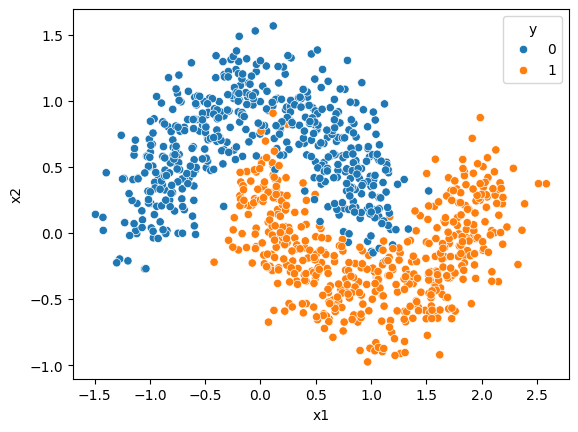

In [23]:
sns.scatterplot(x=df['x1'], y=df['x2'], hue=df['y'])
plt.show()

In [24]:
x = df.iloc[:, :-1]
y = df['y']

x.ndim, y.ndim

(2, 1)

In [25]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

## Decision Tree

In [26]:
dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)

DecisionTreeClassifier()

In [27]:
dt.score(x_test, y_test), dt.score(x_train, y_train)

(0.95, 1.0)

## SVM

In [28]:
sv = SVC()
sv.fit(x_train, y_train)

SVC()

In [29]:
sv.score(x_test, y_test), sv.score(x_train, y_train)

(0.975, 0.9725)

## Naive Bayes

In [30]:
nb = GaussianNB()
nb.fit(x_train, y_train)

GaussianNB()

In [31]:
nb.score(x_test, y_test), nb.score(x_train, y_train)

(0.865, 0.86875)

## Ensemble Learning

In [32]:
from sklearn.ensemble import VotingClassifier

In [39]:
li = [("dt1", DecisionTreeClassifier()), ("svc1", SVC()), ("nb1", GaussianNB())]

wei = [2, 5, 1]

In [40]:
# vc = VotingClassifier(li)

vc = VotingClassifier(li, weights=wei)
vc.fit(x_train, y_train)

VotingClassifier(estimators=[('dt1', DecisionTreeClassifier()), ('svc1', SVC()),
                             ('nb1', GaussianNB())],
                 weights=[2, 5, 1])

In [41]:
vc.score(x_test, y_test), vc.score(x_train, y_train)

(0.975, 0.9725)

In [42]:
pred = {
    "dt": dt.predict(x_test),
    "sv": sv.predict(x_test),
    "nb": nb.predict(x_test),
    "vc": vc.predict(x_test),
}

In [43]:
pd.DataFrame(pred)

,dt,sv,nb,vc
0,1,1,0,1
1,0,0,0,0
2,0,0,1,0
3,1,1,0,1
4,1,1,1,1
...,...,...,...,...
195,0,0,0,0
196,0,0,0,0
197,1,1,1,1
198,0,0,0,0


---